# 实践 3：估计证券特征线（SCL）

- 数据：CSMAR（日个股回报率 TRD_Dalyr、指数文件 TRD_Index、无风险利率 TRD_Nrrate）
- 窗口：2021-10-01 至 2026-09-30（5 年，60 个整月）
- 主分析：月度；对照：周度、日度
- 输出：结果/ 下的 csv 与 fig-*.png

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

HERE = Path.cwd()  # notebook 与 data/ 同级
DATA = HERE / "data"
OUT = HERE / "结果"
OUT.mkdir(exist_ok=True)

START, END = "2021-10-01", "2026-09-30"
INDEX_CODE = "000300"          # 沪深 300
NAMES = {"600030": "中信证券", "002475": "立讯精密", "601899": "紫金矿业",
         "000858": "五粮液", "600900": "长江电力"}
ORDER = list(NAMES)

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

## 读数据

In [2]:
def read_csv(pattern, **kw):
    f = glob.glob(str(DATA / pattern))[0]
    return pd.read_csv(f, encoding="utf-8-sig", **kw)

stk = read_csv("日个股回报率文件*/TRD_Dalyr.csv", dtype={"Stkcd": str})
stk["Trddt"] = pd.to_datetime(stk["Trddt"])
stk = stk[(stk.Trddt >= START) & (stk.Trddt <= END)]
ret = stk.pivot(index="Trddt", columns="Stkcd", values="Dretwd")[ORDER]   # 小数口径，缺失 = 停牌

idx = read_csv("指数文件*/TRD_Index.csv", dtype={"Indexcd": str})
idx["Trddt"] = pd.to_datetime(idx["Trddt"])
mkt = (idx[idx.Indexcd == INDEX_CODE].set_index("Trddt")["Retindex"]
       .loc[START:END])                                                     # 小数口径

rf = read_csv("无风险利率文件*/TRD_Nrrate.csv")
rf["Clsdt"] = pd.to_datetime(rf["Clsdt"])
rf_day = rf.set_index("Clsdt")["Nrrdaydt"] / 100                            # 表里是 %，转成小数；每个日历日一条
# 日历日累计因子：C(t) = prod(1 + rf_d)，用来算任意区间的无风险收益
C = (1 + rf_day).cumprod()
C.loc[C.index.min() - pd.Timedelta(days=1)] = 1.0
C = C.sort_index()

trade_days = mkt.index
assert set(ret.index) <= set(trade_days)


def rf_between(prev_end, end):
    """(prev_end, end] 区间内的无风险收益（按日历日复利）"""
    return C.loc[end] / C.loc[prev_end] - 1

## 构造各频率的超额收益

In [3]:
def make_period_returns(freq):
    """freq: 'D' / 'W' / 'M'。返回 (超额收益表, 市场超额收益)"""
    # 把停牌日的个股收益当作 0（价格没变），复牌日收益已含停牌期间累计变化，连乘后不重复计算
    r = ret.reindex(trade_days).fillna(0.0)
    if freq == "D":
        key = pd.Series(trade_days, index=trade_days)
    elif freq == "W":
        key = pd.Series(trade_days.to_period("W-FRI"), index=trade_days)
    else:
        key = pd.Series(trade_days.to_period("M"), index=trade_days)
    g = key.groupby(key)
    ends = g.apply(lambda s: s.index.max())          # 每期最后一个交易日
    # 期收益 = 日收益连乘
    stk_p = (1 + r).groupby(key.values).prod() - 1
    mkt_p = (1 + mkt).groupby(key.values).prod() - 1
    # 无风险：从上一期末（不含）到本期末（含），按日历日复利
    prev = ends.shift(1)
    prev.iloc[0] = C.index.min()                       # 第一期从窗口起点之前开始
    rf_p = pd.Series([rf_between(p, e) for p, e in zip(prev, ends)], index=ends.index)
    ex = stk_p.sub(rf_p.values, axis=0)
    ex_m = mkt_p - rf_p.values
    ex.index = ends.values
    ex_m.index = ends.values
    return ex, ex_m


def daily_excess_dropping_suspension():
    """日度回归：对每只股票剔除停牌日和复牌日（复牌日收益是多日累计）"""
    out = {}
    ex_all, ex_m = make_period_returns("D")
    for c in ORDER:
        s = ex_all[c].copy()
        have = ret[c].reindex(trade_days).notna()
        # 复牌日：上一交易日停牌
        resume = have & (~have.shift(1, fill_value=True))
        keep = have & ~resume
        out[c] = (s[keep.values], ex_m[keep.values])
    return out

## 回归与方差分析

In [4]:
def scl(y, x):
    X = sm.add_constant(x.values)
    m = sm.OLS(y.values, X).fit()
    n = len(y)
    ss_res = float((m.resid ** 2).sum())
    var_y = float(np.var(y.values, ddof=1))
    var_x = float(np.var(x.values, ddof=1))
    beta = m.params[1]
    sys_var = beta ** 2 * var_x
    nonsys = ss_res / (n - 1)
    return {
        "n": n, "alpha": m.params[0], "se_alpha": m.bse[0], "t_alpha": m.tvalues[0], "p_alpha": m.pvalues[0],
        "beta": beta, "se_beta": m.bse[1], "t_beta": m.tvalues[1], "p_beta": m.pvalues[1],
        "R2": m.rsquared, "sigma_e": np.sqrt(ss_res / (n - 2)),
        "total_var": var_y, "sys_var": sys_var, "nonsys_var": nonsys,
        "sys_share": sys_var / var_y, "resid": pd.Series(m.resid, index=y.index),
    }


def run(freq):
    if freq == "D":
        pairs = daily_excess_dropping_suspension()
    else:
        ex, ex_m = make_period_returns(freq)
        pairs = {c: (ex[c], ex_m) for c in ORDER}
    rows, resids = [], {}
    for c in ORDER:
        y, x = pairs[c]
        res = scl(y, x)
        resids[c] = res.pop("resid")
        rows.append({"代码": c, "简称": NAMES[c], **res})
    return pd.DataFrame(rows).set_index("代码"), pd.DataFrame(resids)


results = {}
for freq, label in [("M", "月度"), ("W", "周度"), ("D", "日度")]:
    tab, resid = run(freq)
    results[freq] = (tab, resid)
    tab.round(6).to_csv(OUT / f"01-特征线回归-{label}.csv", encoding="utf-8-sig")

tab_m, resid_m = results["M"]
ex_m_all, mk_m = make_period_returns("M")

# 00 数据概览
rows = []
for c in ORDER:
    s = ret[c]
    rows.append({"代码": c, "简称": NAMES[c], "首个交易日": s.dropna().index.min().date(),
                 "末个交易日": s.dropna().index.max().date(), "日观测数": int(s.notna().sum()),
                 "缺失（停牌）日": int(len(trade_days) - s.notna().sum()),
                 "日均收益(%)": s.mean() * 100, "日标准差(%)": s.std() * 100})
rows.append({"代码": INDEX_CODE, "简称": "沪深300", "首个交易日": mkt.index.min().date(),
             "末个交易日": mkt.index.max().date(), "日观测数": int(mkt.notna().sum()),
             "缺失（停牌）日": 0, "日均收益(%)": mkt.mean() * 100, "日标准差(%)": mkt.std() * 100})
pd.DataFrame(rows).round(4).to_csv(OUT / "00-数据概览.csv", index=False, encoding="utf-8-sig")

# 02 方差分析（月度）
va = tab_m[["简称", "total_var", "sys_var", "nonsys_var", "sys_share", "R2"]].copy()
va["total_sd(%)"] = np.sqrt(va["total_var"]) * 100
va["sys_sd(%)"] = np.sqrt(va["sys_var"]) * 100
va["nonsys_sd(%)"] = np.sqrt(va["nonsys_var"]) * 100
va.round(6).to_csv(OUT / "02-方差分析-月度.csv", encoding="utf-8-sig")

# 03 残差相关（月度）
resid_m.rename(columns=NAMES).corr().round(3).to_csv(OUT / "03-残差相关-月度.csv", encoding="utf-8-sig")
ex_m_all.rename(columns=NAMES).corr().round(3).to_csv(OUT / "03b-超额收益相关-月度.csv", encoding="utf-8-sig")

# 04 SML（月度，选做）：平均超额收益对 beta
avg = ex_m_all.mean()
sml_df = pd.DataFrame({"beta": tab_m["beta"], "avg_excess": avg.reindex(tab_m.index)})
Xs = sm.add_constant(sml_df["beta"].values)
sml = sm.OLS(sml_df["avg_excess"].values, Xs).fit()
sml_out = pd.DataFrame({"系数": sml.params, "标准误": sml.bse, "t": sml.tvalues, "p": sml.pvalues},
                       index=["截距(gamma0)", "斜率(gamma1)"])
sml_out["样本市场平均超额收益"] = [np.nan, mk_m.mean()]
sml_out.round(6).to_csv(OUT / "04-SML-月度.csv", encoding="utf-8-sig")
sml_df.assign(简称=[NAMES[c] for c in sml_df.index]).round(6).to_csv(
    OUT / "04-SML散点数据-月度.csv", encoding="utf-8-sig")

## 图

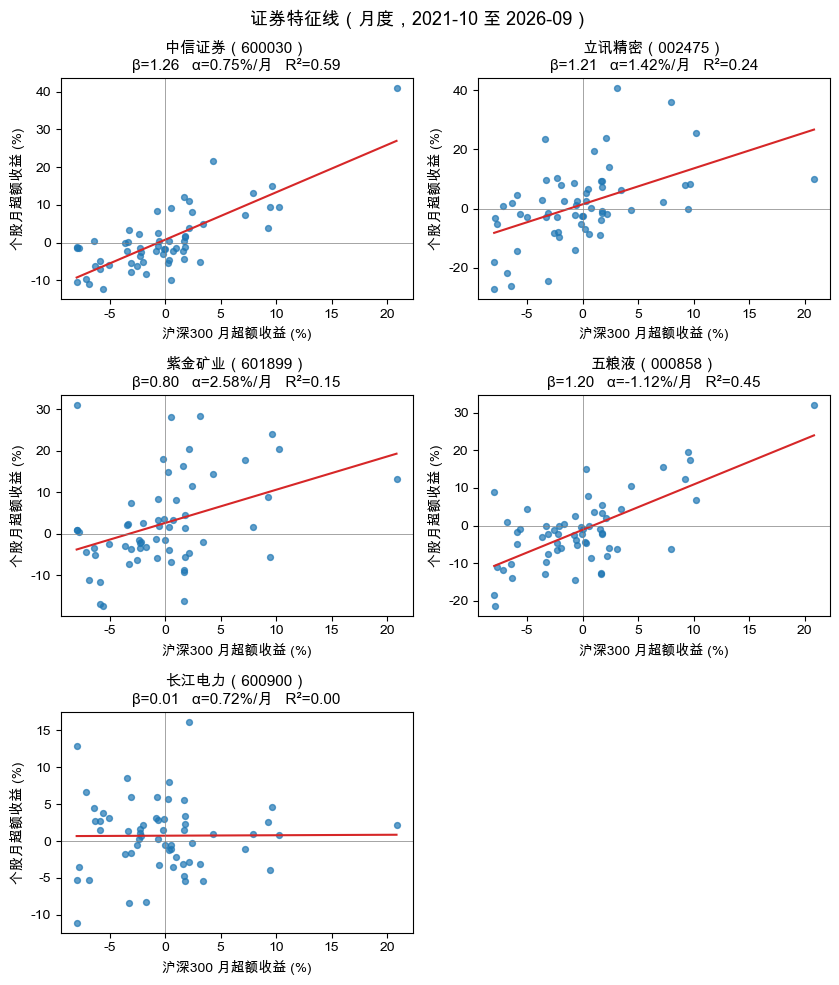

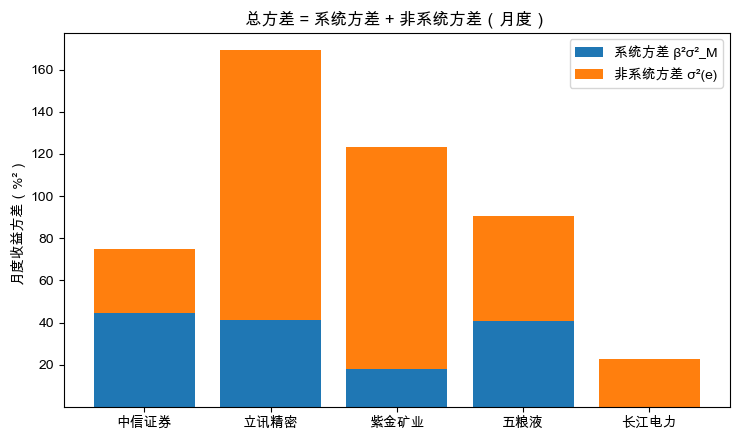

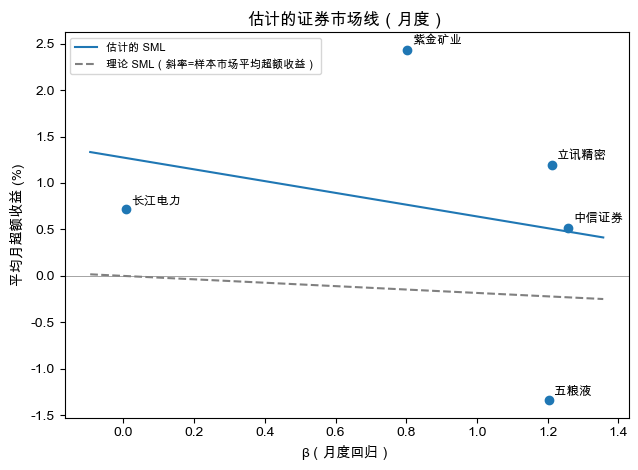

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(8.5, 10))
for ax, c in zip(axes.ravel(), ORDER):
    y, x = ex_m_all[c] * 100, mk_m * 100
    ax.scatter(x, y, s=18, alpha=.7)
    b, a = tab_m.loc[c, "beta"], tab_m.loc[c, "alpha"] * 100
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, a + b * xs, color="C3")
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ax.set_title(f"{NAMES[c]}（{c}）\nβ={b:.2f}   α={a:.2f}%/月   R²={tab_m.loc[c,'R2']:.2f}", fontsize=11)
    ax.set_xlabel("沪深300 月超额收益 (%)", fontsize=10); ax.set_ylabel("个股月超额收益 (%)", fontsize=10)
axes.ravel()[-1].axis("off")
fig.suptitle("证券特征线（月度，2021-10 至 2026-09）", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "fig-01-特征线散点-月度.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
names = [NAMES[c] for c in ORDER]
sys_sd = np.sqrt(tab_m["sys_var"]).values * 100
non_sd = np.sqrt(tab_m["nonsys_var"]).values * 100
ax.bar(names, tab_m["sys_var"].values * 1e4, label="系统方差 β²σ²_M")
ax.bar(names, tab_m["nonsys_var"].values * 1e4, bottom=tab_m["sys_var"].values * 1e4, label="非系统方差 σ²(e)")
ax.set_ylabel("月度收益方差（%²）"); ax.legend(); ax.set_title("总方差 = 系统方差 + 非系统方差（月度）")
fig.tight_layout(); fig.savefig(OUT / "fig-02-方差分解-月度.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.scatter(sml_df["beta"], sml_df["avg_excess"] * 100)
for c in ORDER:
    ax.annotate(NAMES[c], (sml_df.loc[c, "beta"], sml_df.loc[c, "avg_excess"] * 100),
                xytext=(4, 4), textcoords="offset points", fontsize=9)
xs = np.linspace(sml_df["beta"].min() - .1, sml_df["beta"].max() + .1, 30)
ax.plot(xs, (sml.params[0] + sml.params[1] * xs) * 100, label="估计的 SML")
ax.plot(xs, mk_m.mean() * xs * 100, "--", color="gray", label="理论 SML（斜率=样本市场平均超额收益）")
ax.axhline(0, color="gray", lw=.5)
ax.set_xlabel("β（月度回归）"); ax.set_ylabel("平均月超额收益 (%)"); ax.legend(fontsize=8)
ax.set_title("估计的证券市场线（月度）")
fig.tight_layout(); fig.savefig(OUT / "fig-03-SML-月度.png", dpi=150); plt.show()

## 终端摘要

In [6]:
pd.set_option("display.width", 200, "display.max_columns", 30)
print("== 月度回归（n=60）")
print(tab_m[["简称", "n", "alpha", "t_alpha", "beta", "se_beta", "R2", "sys_share"]].round(4))
for f, lab in [("W", "周度"), ("D", "日度")]:
    t = results[f][0]
    print(f"== {lab}回归")
    print(t[["简称", "n", "alpha", "t_alpha", "beta", "se_beta", "R2"]].round(4))
print("== 样本期：市场月平均超额收益 = %.4f%%/月; rf 月均 = %.4f%%" % (
    mk_m.mean() * 100, ((1 + mkt).groupby(mkt.index.to_period('M')).prod() - 1 - mk_m.values).mean() * 100))
print("== SML（月度，5 点）")
print(sml_out.round(5))
print("== 月度残差相关")
print(resid_m.rename(columns=NAMES).corr().round(2))

== 月度回归（n=60）
          简称   n   alpha  t_alpha    beta  se_beta      R2  sys_share
代码                                                                   
600030  中信证券  60  0.0075   1.0414  1.2571   0.1372  0.5915     0.5915
002475  立讯精密  60  0.0142   0.9639  1.2113   0.2803  0.2436     0.2436
601899  紫金矿业  60  0.0258   1.9292  0.8018   0.2543  0.1464     0.1464
000858   五粮液  60 -0.0112  -1.2159  1.2034   0.1748  0.4498     0.4498
600900  长江电力  60  0.0072   1.1519  0.0062   0.1187  0.0000     0.0000
== 周度回归
          简称    n   alpha  t_alpha    beta  se_beta      R2
代码                                                         
600030  中信证券  254  0.0018   1.0789  1.2823   0.0736  0.5465
002475  立讯精密  254  0.0030   0.9917  1.2119   0.1347  0.2431
601899  紫金矿业  254  0.0060   2.1594  0.9168   0.1220  0.1831
000858   五粮液  254 -0.0027  -1.3308  1.2989   0.0881  0.4632
600900  长江电力  254  0.0017   1.2259  0.1071   0.0621  0.0117
== 日度回归
          简称     n   alpha  t_alpha    beta  se_beta      R2

## 自检（写入 结果/05-自检.csv）

In [7]:
chk = []
max_beta_diff = max(abs(tab_m.loc[c, "beta"]
                        - np.cov(ex_m_all[c], mk_m, ddof=1)[0, 1] / np.var(mk_m, ddof=1)) for c in ORDER)
chk.append(("斜率 = Cov(y,x)/Var(x)", f"{max_beta_diff:.2e}", "最大绝对差 < 1e-10"))
max_split = float((tab_m["total_var"] - tab_m["sys_var"] - tab_m["nonsys_var"]).abs().max())
chk.append(("总方差 = 系统方差 + 非系统方差", f"{max_split:.2e}", "最大绝对差 < 1e-10"))
max_rc = max(abs(np.cov(resid_m[c], mk_m, ddof=1)[0, 1]) for c in ORDER)
chk.append(("残差与市场的样本协方差 = 0", f"{max_rc:.2e}", "最大绝对值 < 1e-10"))
chk.append(("月度期数", str(len(mk_m)), "60"))
chk.append(("周度期数", str(len(make_period_returns('W')[1])), "—"))
chk.append(("月度超额收益缺失值个数", str(int(ex_m_all.isna().sum().sum() + mk_m.isna().sum())), "0"))
pd.DataFrame(chk, columns=["检查项", "结果", "要求"]).to_csv(OUT / "05-自检.csv", index=False, encoding="utf-8-sig")
print(pd.DataFrame(chk, columns=["检查项", "结果", "要求"]).to_string(index=False))

                 检查项       结果            要求
斜率 = Cov(y,x)/Var(x) 1.11e-15 最大绝对差 < 1e-10
  总方差 = 系统方差 + 非系统方差 6.94e-18 最大绝对差 < 1e-10
     残差与市场的样本协方差 = 0 2.48e-18 最大绝对值 < 1e-10
                月度期数       60            60
                周度期数      254             —
         月度超额收益缺失值个数        0             0
